# Xenium Prime 5K Breast — expression-only GNN communication niches

Select the **cccphe** kernel and use **Run All**. This notebook invokes existing project modules to prepare and audit the real inputs, train the current model when needed, and display its results. A complete result with matching configuration is reused. New outputs are independent of archived AE/GNN results and remain on NAS. This is an independent downstream single-tissue analysis; no clinical/phenotype/TLS supervision enters the clinical CCC/Cox mainline.

Current training uses CCC reconstruction + program regularization only (lambda_comp=0, lambda_reg=0.005). Cell-type composition reconstruction is disabled. Restart Kernel / Run All to use this configuration. Results are stored in an independent NAS directory; archived composition-constrained models remain unchanged.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,json
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.gnn.config import GNNConfig
from phenoniche.ccc.config import default_config
from phenoniche.gnn.pipeline import ensure_results
from phenoniche.gnn.reporting import GNNReport
CONFIG=ROOT/'config/gnn.json'
config=GNNConfig.from_json(CONFIG)
OUTPUT=Path(config.output_dir)
pd.set_option('display.max_colwidth',150)
pd.set_option('display.max_rows',200)
def show(fig):
    display(fig)
    plt.close(fig)

## 1. Real data and model configuration

The current LR expression coverage filter is 5%. The encoder receives expression and geometry only. Cell types supply directed CCC labels and downstream annotations only; they are not encoder inputs or composition reconstruction supervision. Expression normalization, feature scaling, and the effective CCC mask are fitted only on training spatial blocks. No CollecTRI/NicheNet supervision or regulatory target holdout is used.

In [2]:
input_config=default_config()
adata=ad.read_h5ad(input_config.processed_h5ad,backed='r')
try:
    display(pd.Series({'cells':adata.n_obs,'panel_genes':adata.n_vars,'dataset':adata.uns.get('dataset'),'expression_coverage_fraction':input_config.expression_coverage_fraction}).to_frame('Input'))
finally:
    adata.file.close()
display(pd.Series(config.to_dict()).to_frame('Model configuration'))
print('NAS outputs:',OUTPUT)

,Input
cells,699110
panel_genes,5101
dataset,Xenium_Prime_Breast_Cancer_FFPE
expression_coverage_fraction,0.05


,Model configuration
seed,40700
split_seed,40700
programs,32
hidden,64
encoder_genes,512
batch_size,512
max_epochs,40
patience,6
lr,0.003
weight_decay,0.0001


NAS outputs: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/microenvironment_gnn_ccc_only_expr05


## 2. Prepare, audit, train/reuse, and infer

Run All constructs/audits the unchanged directed CCC target and applies the repository audit gate. Spatial splits purge shared physical cells. Matching complete results and compatible checkpoints are reused; archived incompatible checkpoints are protected.

Z = aP, P = Softmax(f(G)), C_hat = ZH. H is nonnegative with unit row sums.

L = L_CCC + 0.005 L_regularization. There is no cell-type composition reconstruction loss. Cell composition is used for descriptive downstream diagnostics only.

In [3]:
summary=ensure_results(CONFIG)
report=GNNReport(OUTPUT)
display(report.overview())
display(report.features.head(12))
display(pd.Series(summary).to_frame('Saved analysis summary'))

,Value
Cells / microenvironments,699110
Xenium genes,5101
Fixed directed CCC features,2374
Effective training features,1821
Expression input genes,512
Cell-type encoder input,False
Communication programs,32
Selected niches,4
Composition weight,0.0
Undefined composition centers (masked),17


,feature_id,flat_feature_index,sender,receiver,lr_id,ligand,receptor,ccc
0,0,2085,B cell,B cell,CommuSpace_HS_06177,PKM,CD44,B cell → B cell | PKM–CD44
1,1,2348,B cell,B cell,CommuSpace_HS_06996,SLAMF7,SLAMF7,B cell → B cell | SLAMF7–SLAMF7
2,2,2547,B cell,B cell,CommuSpace_HS_07452,TIMP3,CD44,B cell → B cell | TIMP3–CD44
3,3,3014,B cell,Endothelial,CommuSpace_HS_00413,ARF1,INSR,B cell → Endothelial | ARF1–INSR
4,4,3340,B cell,Endothelial,CommuSpace_HS_01181,CD44,SELE,B cell → Endothelial | CD44–SELE
5,5,3655,B cell,Endothelial,CommuSpace_HS_02342,DCN,KDR,B cell → Endothelial | DCN–KDR
6,6,4240,B cell,Endothelial,CommuSpace_HS_03965,GNAI2,F2R,B cell → Endothelial | GNAI2–F2R
7,7,4251,B cell,Endothelial,CommuSpace_HS_03976,GNAI2,S1PR1,B cell → Endothelial | GNAI2–S1PR1
8,8,4794,B cell,Endothelial,CommuSpace_HS_05571,NAMPT,INSR,B cell → Endothelial | NAMPT–INSR
9,9,4795,B cell,Endothelial,CommuSpace_HS_05572,NAMPT,ITGA5,B cell → Endothelial | NAMPT–ITGA5


,Saved analysis summary
composition_undefined_centers,17
composition_to_Z_test_R2,0.401869
composition_only_niche_test_accuracy,0.832737
dominant_niche_test_fraction,0.39149
test_spatial_neighbor_agreement,0.926534
effective_programs,9.987556
maximum_dictionary_cosine,0.398711
dictionary_entropy,0.981851
interpretation,"Single-tissue association diagnostics; composition is auxiliary supervision, not evidence of causality or phenotype."
selected_K,4


## 3. Training curves and held-out CCC reconstruction

Train/validation/test centers do not share physical cells. Only CCC reconstruction and regularization contribute to the training objective.

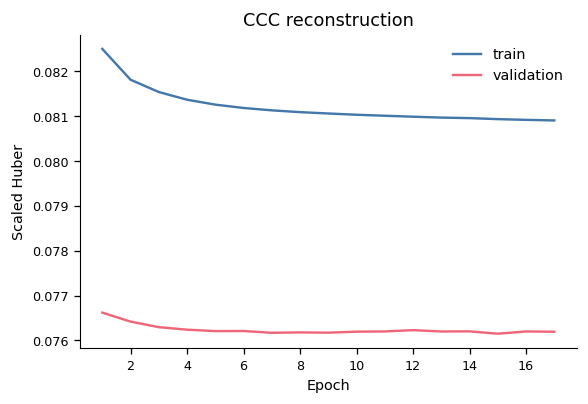

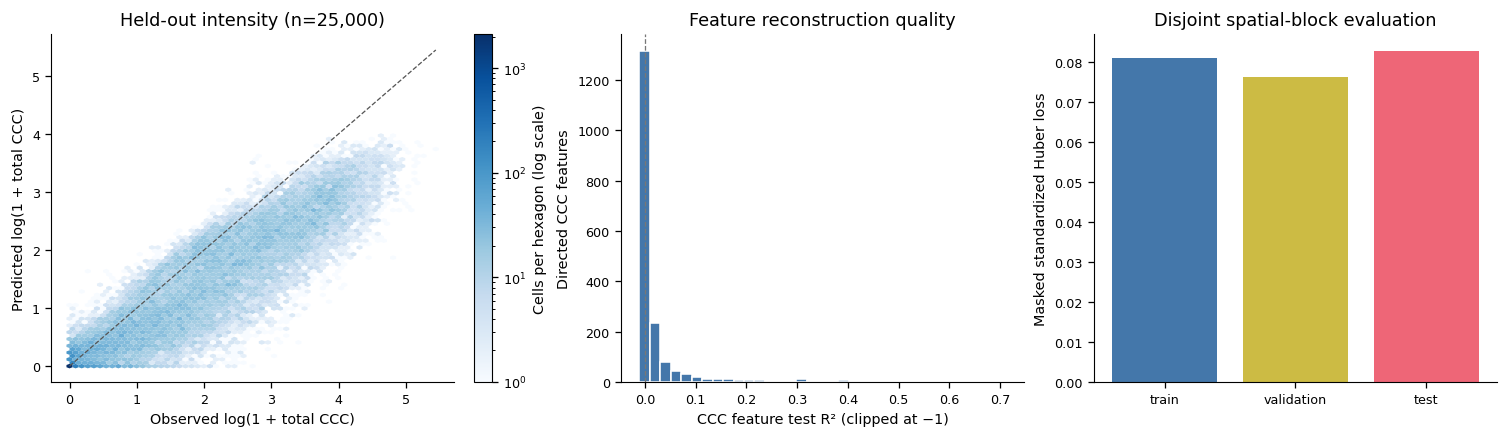

,n,scaled_huber,median_feature_R2
train,359883.0,0.080970,0.001126
validation,107313.0,0.076199,0.000846
test,112368.0,0.082888,0.000918


,Held-out evaluation
best_epoch,11
validation_loss,0.077346
test,"{'ccc': 0.08288751086919002, 'regularization': 0.2359731908445767, 'total': 0.0840673768234129}"


In [4]:
show(report.training_curves())
show(report.reconstruction())
display(pd.DataFrame(report.reconstruction_metrics).T)
display(pd.Series(json.loads((OUTPUT/'heldout_metrics.json').read_text())).to_frame('Held-out evaluation'))

## 4. All 32 communication programs and CCC dictionary H

Absolute Z preserves total communication activity; P describes relative communication-program activity. H traces each program to sender → receiver → LR features. The H heatmap highlights representative features; full H is exported as CSV. No composition decoder is trained or shown.

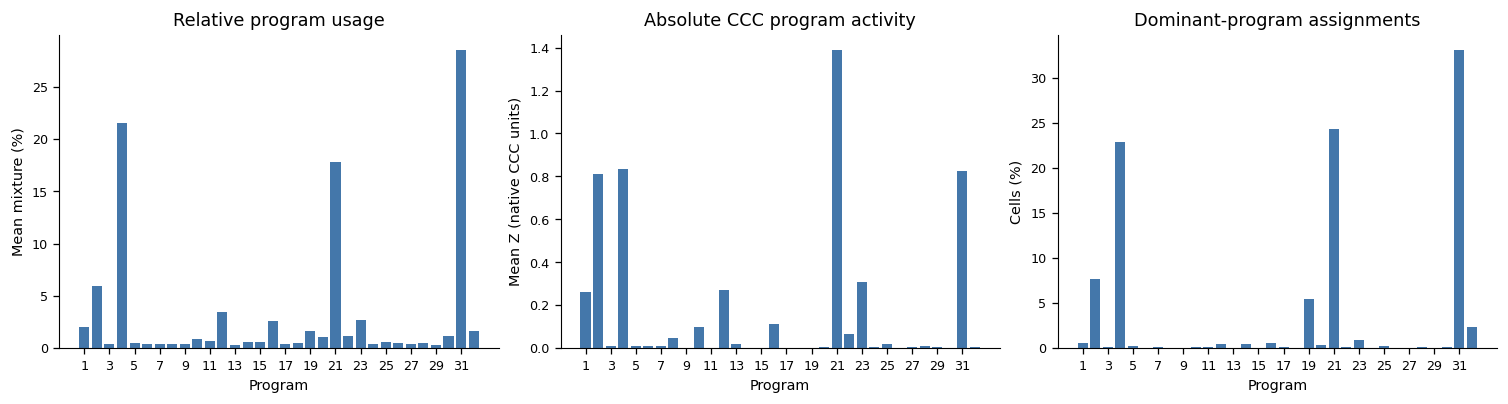

,program,mean_mixture,mean_exposure,dominant_fraction
0,1,0.020055,0.262140,0.005533
1,2,0.058867,0.811929,0.076072
2,3,0.004059,0.007087,0.000669
3,4,0.215201,0.836300,0.229167
4,5,0.004959,0.008449,0.001817
5,6,0.004214,0.008262,0.000016
6,7,0.004174,0.009032,0.000519
7,8,0.003826,0.047477,0.000154
8,9,0.003319,0.001801,0.000116
9,10,0.008887,0.096416,0.001006


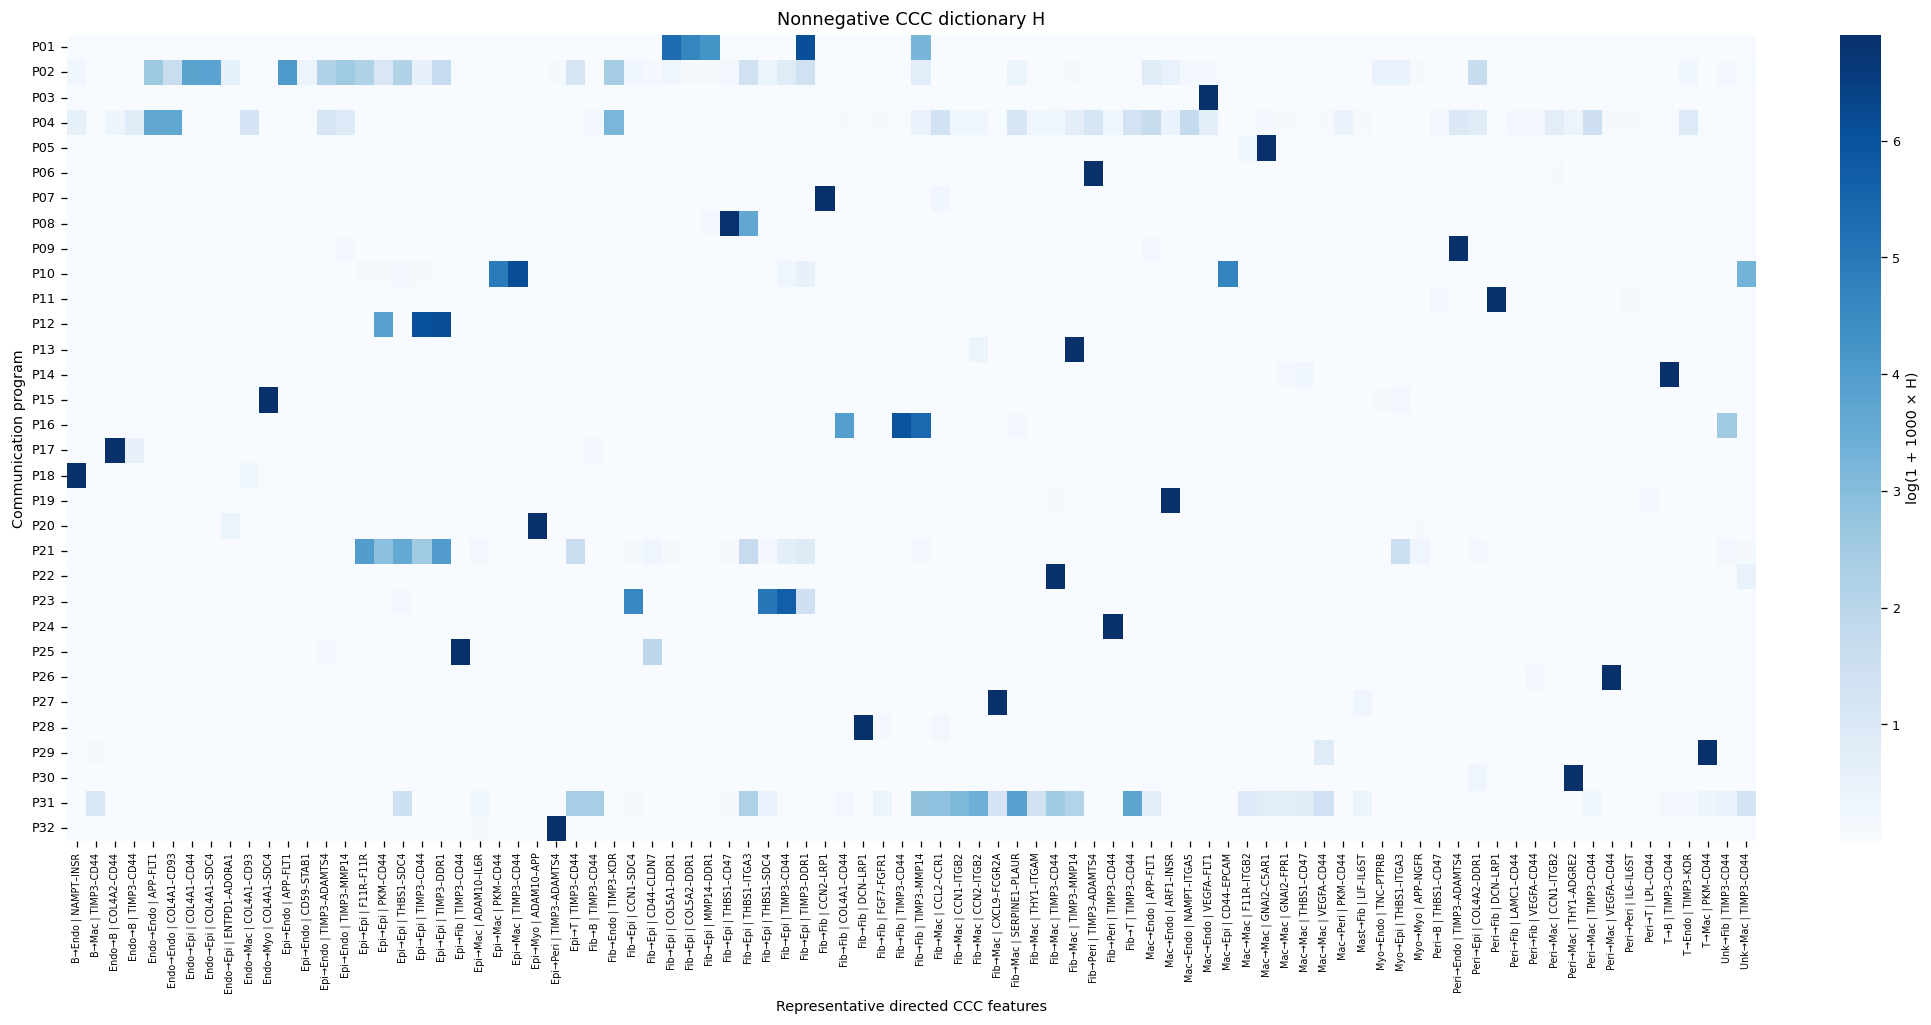

,program,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
0,1,1,907,Fibroblast → Epithelial | TIMP3–DDR1,Fibroblast,Epithelial,TIMP3,DDR1,0.446382
1,1,2,865,Fibroblast → Epithelial | COL5A1–DDR1,Fibroblast,Epithelial,COL5A1,DDR1,0.193727
2,1,3,867,Fibroblast → Epithelial | COL5A2–DDR1,Fibroblast,Epithelial,COL5A2,DDR1,0.103275
3,1,4,884,Fibroblast → Epithelial | MMP14–DDR1,Fibroblast,Epithelial,MMP14,DDR1,0.069705
4,1,5,866,Fibroblast → Epithelial | COL5A1–ITGA2,Fibroblast,Epithelial,COL5A1,ITGA2,0.033753
15,2,1,459,Epithelial → Endothelial | APP–FLT1,Epithelial,Endothelial,APP,FLT1,0.057650
16,2,2,156,Endothelial → Epithelial | COL4A1–SDC4,Endothelial,Epithelial,COL4A1,SDC4,0.043132
17,2,3,153,Endothelial → Epithelial | COL4A1–CD44,Endothelial,Epithelial,COL4A1,CD44,0.042246
18,2,4,158,Endothelial → Epithelial | COL4A2–DDR1,Endothelial,Epithelial,COL4A2,DDR1,0.036418
19,2,5,154,Endothelial → Epithelial | COL4A1–CD47,Endothelial,Epithelial,COL4A1,CD47,0.035580


In [5]:
fig,usage=report.program_usage();show(fig);display(usage)
show(report.dictionary_heatmap())
display(pd.read_csv(OUTPUT/'programs/top_ccc.csv').groupby('program').head(5))

## 5. Select K = 4–15 and identify communication-defined niches

Clustering is based on communication-program mixture and activity from Z. K is fitted on training blocks and selected on validation blocks; test blocks are reserved for final diagnostics. Seed stability refers to clustering seeds, not independent GNN retraining.

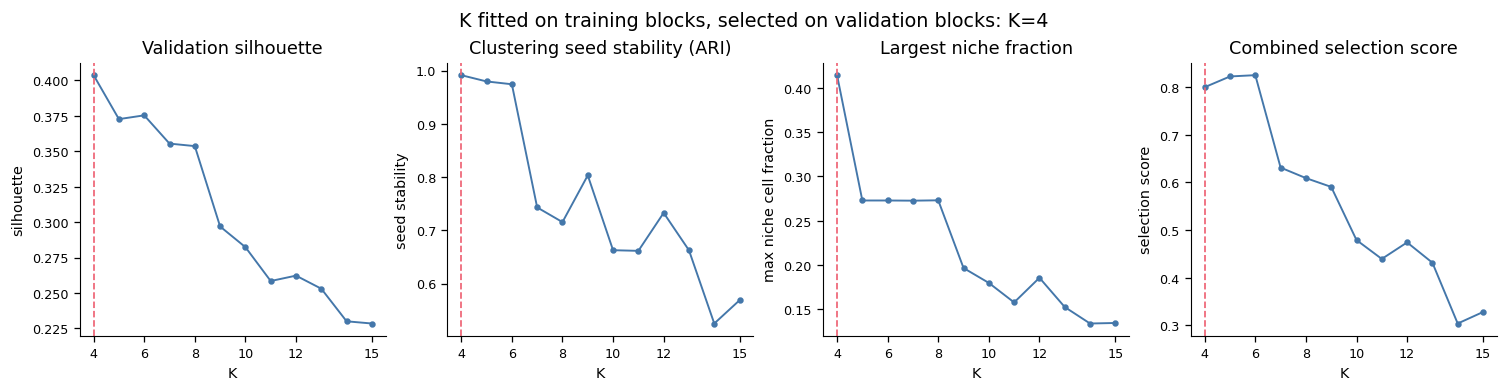

,K,silhouette,seed_stability,max_niche_cell_fraction,tiny_niche_fraction,active_niches,selection_score,eligible,selected
0,4,0.403645,0.991350,0.4142,0.0,4,0.800000,True,True
1,5,0.372635,0.979572,0.2728,0.0,5,0.822557,True,False
2,6,0.375304,0.974286,0.2728,0.0,6,0.825251,True,False
3,7,0.355371,0.742955,0.2726,0.0,7,0.631103,True,False
4,8,0.353598,0.715388,0.2730,0.0,8,0.609041,True,False
5,9,0.296888,0.803121,0.1966,0.0,9,0.590532,True,False
6,10,0.282316,0.662591,0.1798,0.0,10,0.478873,True,False
7,11,0.258407,0.661387,0.1578,0.0,11,0.439217,True,False
8,12,0.262218,0.732717,0.1856,0.0,12,0.473950,True,False
9,13,0.252984,0.662499,0.1526,0.0,13,0.431262,True,False


In [6]:
show(report.k_selection())
display(report.selection)

## 6. Tissue-space maps, individual niches, composition and enrichment

All cell centers use original micrometer coordinates. Enrichment is descriptive within one tissue; overlapping microenvironments are not independent biological replicates. The local composition plot uses the exact pair-weighted composition target.

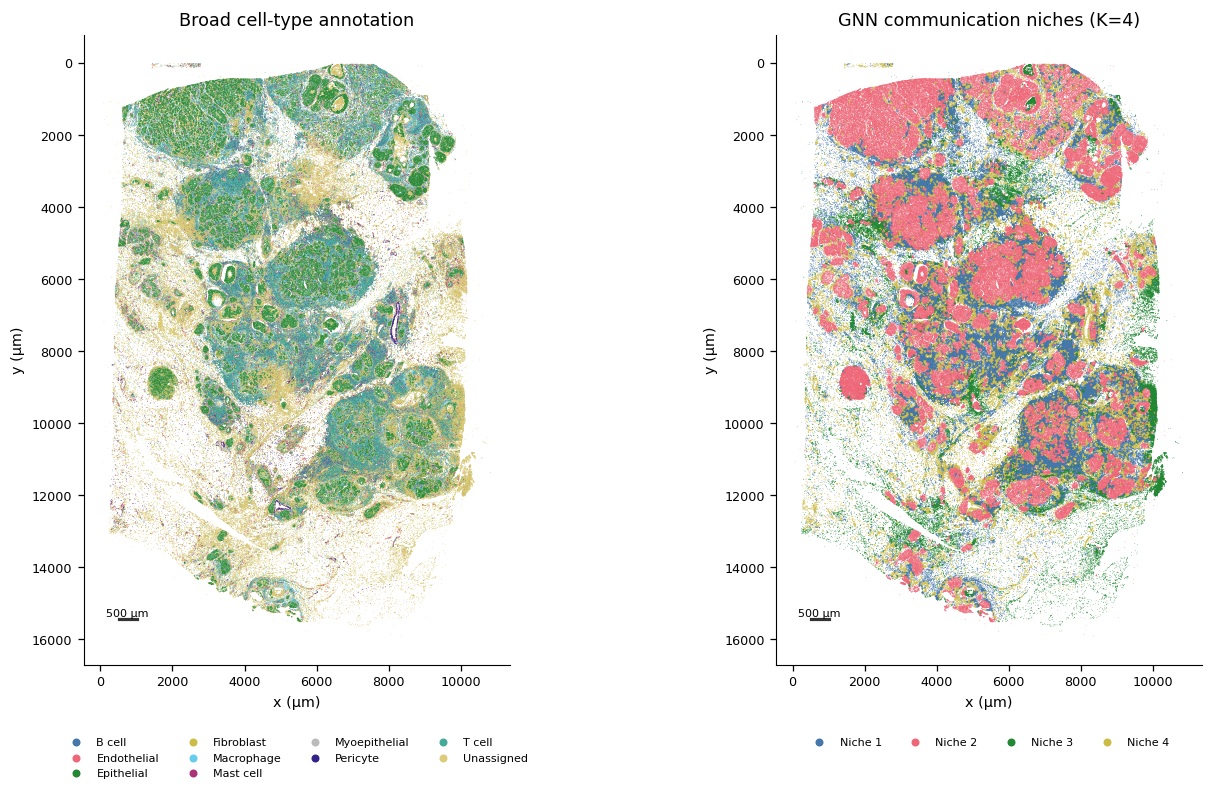

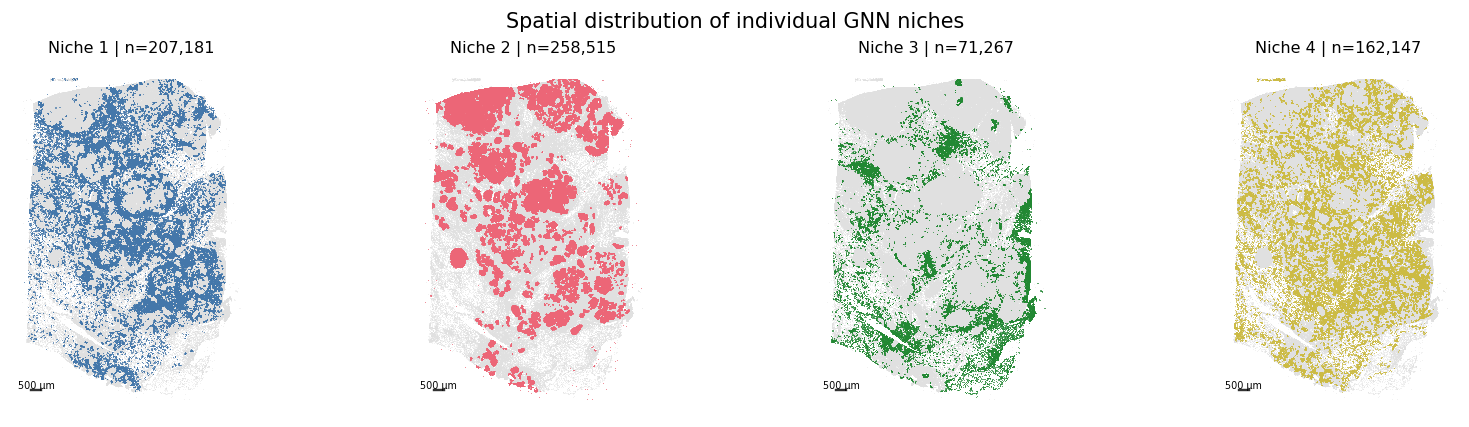

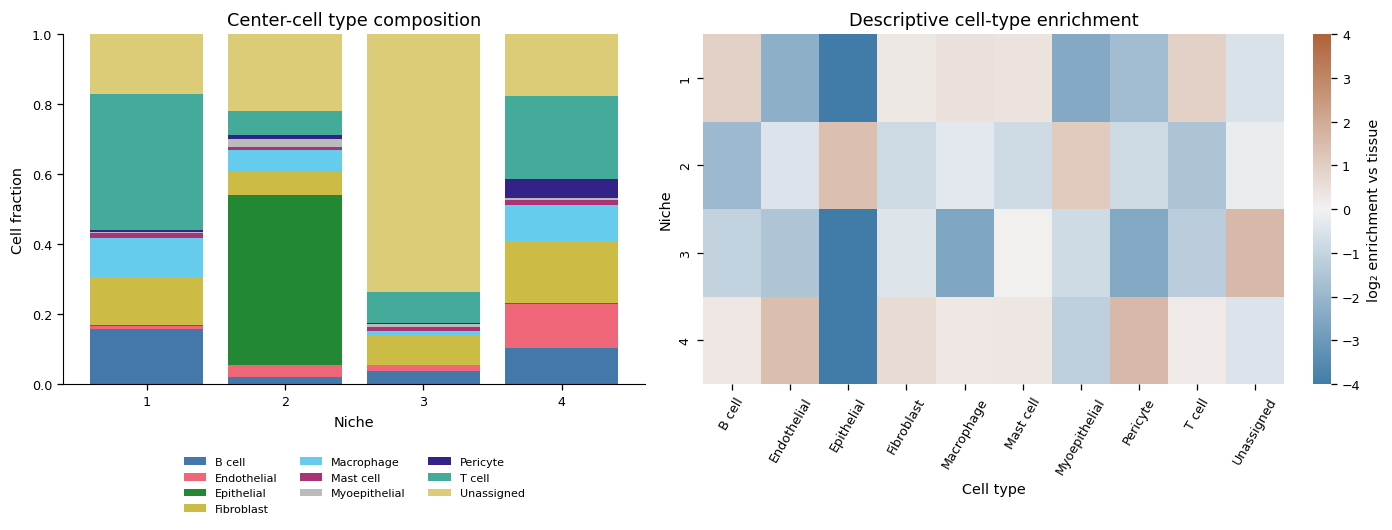

cell_type,B cell,Endothelial,Epithelial,Fibroblast,Macrophage,Mast cell,Myoepithelial,Pericyte,T cell,Unassigned
niche,,,,,,,,,,
1,0.157457,0.009509,0.001545,0.137102,0.110918,0.016662,0.001960,0.005261,0.389959,0.169629
2,0.021933,0.032714,0.485867,0.064724,0.065099,0.007419,0.022943,0.010328,0.069891,0.219082
3,0.038798,0.016052,0.000126,0.083054,0.013807,0.012937,0.006258,0.003269,0.087881,0.737817
4,0.102265,0.126583,0.002424,0.178431,0.101149,0.015726,0.004909,0.053970,0.238500,0.176044


cell_type,B cell,Endothelial,Epithelial,Fibroblast,Macrophage,Mast cell,Myoepithelial,Pericyte,T cell,Unassigned
niche,,,,,,,,,,
1,0.933419,-2.271378,-6.869310,0.260987,0.439138,0.397660,-2.467225,-1.792595,0.922895,-0.544016
2,-1.910305,-0.488891,1.426997,-0.821893,-0.329638,-0.769418,1.081469,-0.819575,-1.557220,-0.174933
3,-1.087461,-1.515963,-10.471283,-0.462140,-2.566761,0.032677,-0.792581,-2.478769,-1.226793,1.576854
4,0.310786,1.463186,-6.219602,0.641095,0.306134,0.314319,-1.142789,1.565866,0.213564,-0.490467


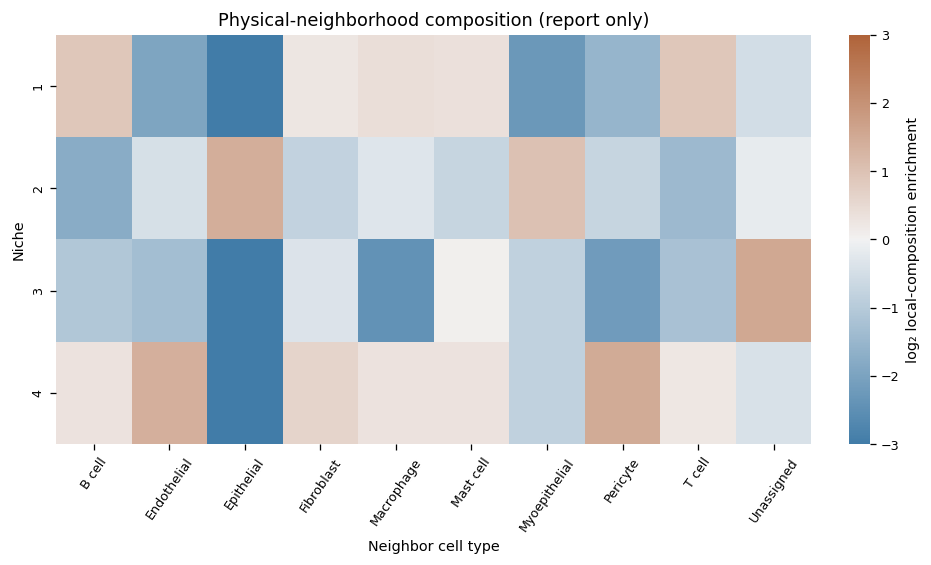

In [7]:
show(report.spatial_overview())
show(report.each_niche())
fig,fraction,enrichment=report.composition();show(fig)
display(fraction)
display(enrichment)
show(report.local_composition())

## 7. Niche × program activity and representative communication

Activity heatmaps use mean Z of assigned cells. Representative niche CCC profiles use training-block soft program contributions, preserving the trained H interpretation. Cell composition is downstream descriptive analysis, not an auxiliary reconstruction task or evidence of causality.

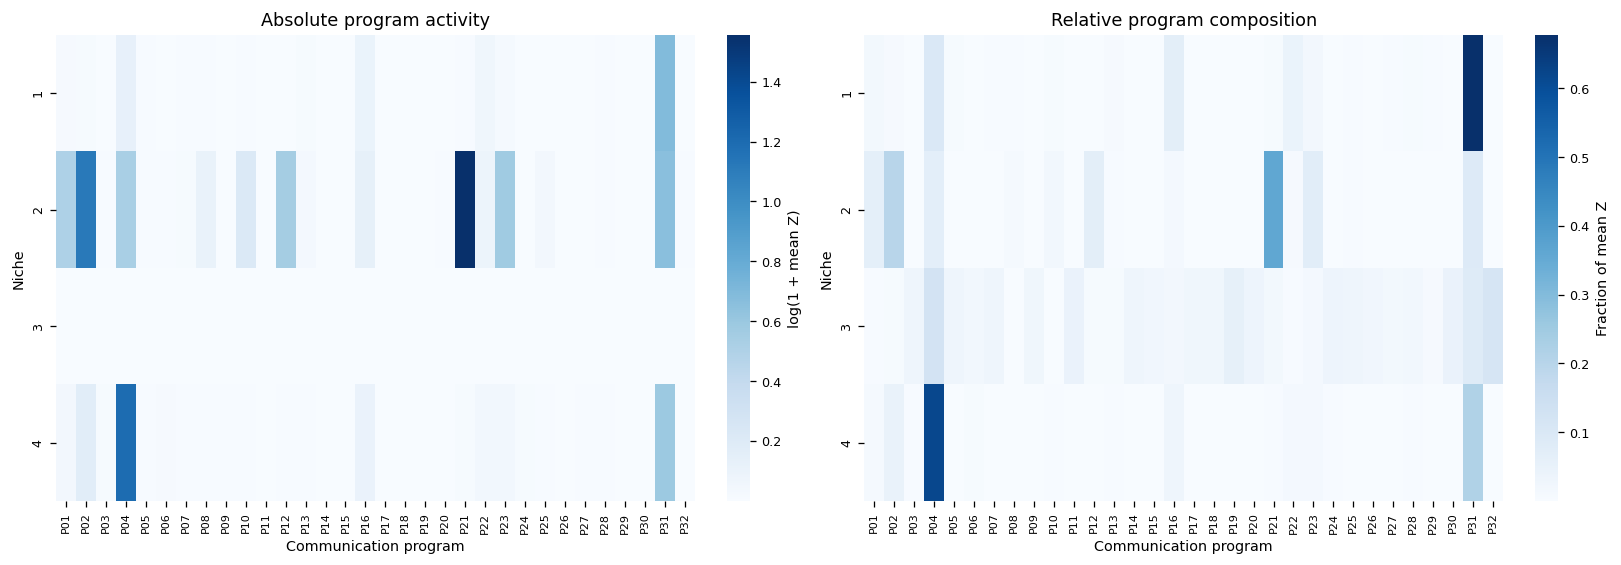

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,...,P23,P24,P25,P26,P27,P28,P29,P30,P31,P32
1,0.023366,0.012905,0.001452,0.143161,0.007977,0.003282,0.006119,0.006880,0.000272,0.008764,...,0.028097,0.002611,0.004869,0.000337,0.005935,0.008974,0.005820,0.000411,0.989419,0.001025
2,0.662689,2.069999,0.009721,0.698287,0.012111,0.006405,0.014418,0.117411,0.000592,0.246689,...,0.776586,0.004137,0.044890,0.000247,0.005125,0.008818,0.003833,0.000320,0.934959,0.006784
3,0.000012,0.000017,0.000075,0.000297,0.000070,0.000056,0.000073,0.000006,0.000063,0.000001,...,0.000034,0.000083,0.000080,0.000057,0.000043,0.000054,0.000022,0.000110,0.000206,0.000273
4,0.044964,0.186736,0.013199,2.310684,0.006922,0.021209,0.008135,0.008915,0.006450,0.011483,...,0.052545,0.012816,0.007916,0.001464,0.006767,0.011783,0.003804,0.000937,0.806434,0.004882


,niche,cells,leading_programs,representative_CCC
0,1,207181,"P31, P04, P16",Fibroblast → Macrophage | TIMP3–CD44; Fibroblast → Macrophage | SERPINE1–PLAUR; Fibroblast → Fibroblast | TIMP3–CD44; Fibroblast → T cell | TIMP3–...
1,2,258515,"P21, P02, P31",Epithelial → Epithelial | TIMP3–DDR1; Epithelial → Epithelial | TIMP3–CD44; Fibroblast → Epithelial | TIMP3–DDR1; Fibroblast → Epithelial | TIMP3–...
2,3,71267,"P04, P31, P32",Epithelial → Pericyte | TIMP3–ADAMTS4; Macrophage → Endothelial | ARF1–INSR; Pericyte → Fibroblast | DCN–LRP1; Pericyte → Macrophage | THY1–ADGRE2...
3,4,162147,"P04, P31, P02",Endothelial → Endothelial | COL4A1–CD93; Endothelial → Endothelial | APP–FLT1; Fibroblast → Macrophage | TIMP3–CD44; Fibroblast → Endothelial | TI...


Niche 1: representative sender–receiver–LR


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
0,1,1,977,Fibroblast → Macrophage | TIMP3–CD44,Fibroblast,Macrophage,TIMP3,CD44,0.047593
1,1,2,968,Fibroblast → Macrophage | SERPINE1–PLAUR,Fibroblast,Macrophage,SERPINE1,PLAUR,0.028954
2,1,3,932,Fibroblast → Fibroblast | TIMP3–CD44,Fibroblast,Fibroblast,TIMP3,CD44,0.025414
3,1,4,1112,Fibroblast → T cell | TIMP3–CD44,Fibroblast,T cell,TIMP3,CD44,0.025346
4,1,5,933,Fibroblast → Fibroblast | TIMP3–MMP14,Fibroblast,Fibroblast,TIMP3,MMP14,0.024660


Niche 2: representative sender–receiver–LR


...

Niche 3: representative sender–receiver–LR


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
30,3,1,756,Epithelial → Pericyte | TIMP3–ADAMTS4,Epithelial,Pericyte,TIMP3,ADAMTS4,0.064629
31,3,2,1127,Macrophage → Endothelial | ARF1–INSR,Macrophage,Endothelial,ARF1,INSR,0.033247
32,3,3,2069,Pericyte → Fibroblast | DCN–LRP1,Pericyte,Fibroblast,DCN,LRP1,0.027935
33,3,4,2132,Pericyte → Macrophage | THY1–ADGRE2,Pericyte,Macrophage,THY1,ADGRE2,0.025704
34,3,5,610,Epithelial → Fibroblast | TIMP3–CD44,Epithelial,Fibroblast,TIMP3,CD44,0.023133


Niche 4: representative sender–receiver–LR


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
45,4,1,96,Endothelial → Endothelial | COL4A1–CD93,Endothelial,Endothelial,COL4A1,CD93,0.023523
46,4,2,84,Endothelial → Endothelial | APP–FLT1,Endothelial,Endothelial,APP,FLT1,0.023302
47,4,3,977,Fibroblast → Macrophage | TIMP3–CD44,Fibroblast,Macrophage,TIMP3,CD44,0.017706
48,4,4,827,Fibroblast → Endothelial | TIMP3–KDR,Fibroblast,Endothelial,TIMP3,KDR,0.014374
49,4,5,828,Fibroblast → Endothelial | TIMP3–MMP14,Fibroblast,Endothelial,TIMP3,MMP14,0.012445


,Diagnostic
composition_undefined_centers,17
composition_to_Z_test_R2,0.401869
composition_only_niche_test_accuracy,0.832737
dominant_niche_test_fraction,0.39149
test_spatial_neighbor_agreement,0.926534
effective_programs,9.987556
maximum_dictionary_cosine,0.398711
dictionary_entropy,0.981851
interpretation,"Single-tissue association diagnostics; composition is auxiliary supervision, not evidence of causality or phenotype."


In [8]:
fig,activity=report.niche_programs();show(fig);display(activity)
overview,ccc=report.interpretation();display(overview)
for niche in range(1,report.k+1):
    print(f'Niche {niche}: representative sender–receiver–LR')
    display(ccc.loc[ccc.niche==niche].head(5))
display(pd.Series(json.loads((OUTPUT/'diagnostics.json').read_text())).to_frame('Diagnostic'))

## 8. Comparison with archived CCC-vector AE

Archived AE weights/results remain unchanged. Spatial maps and cell assignment correspondence are descriptive: the archived model used overlapping random folds and a narrower CCC feature universe. This comparison does not establish comparative generalization or phenotype associations.

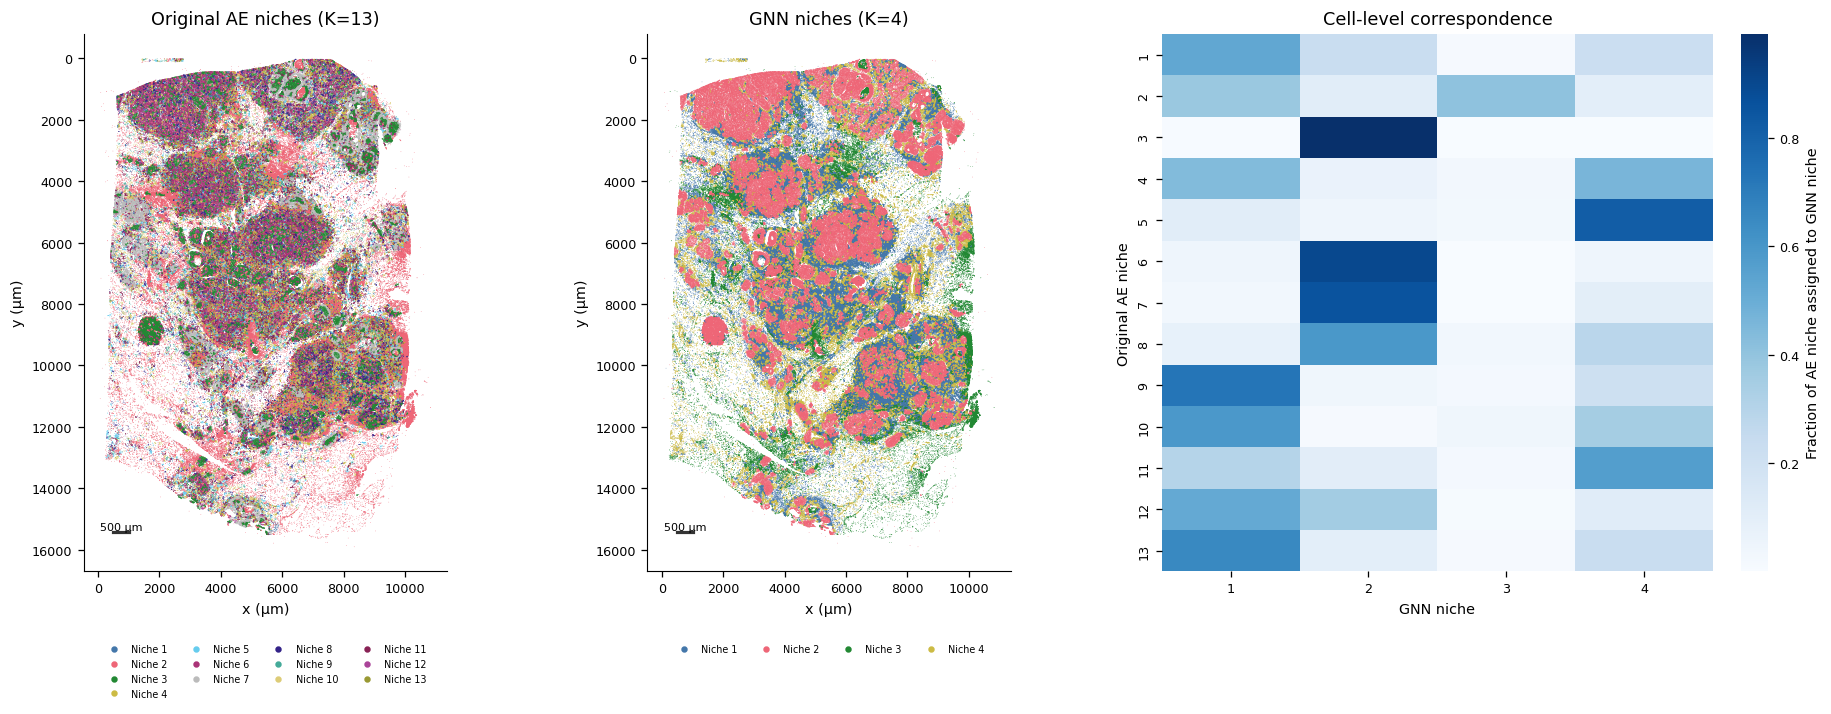

,Value
Cells,699110
Original AE K,13
GNN K,4
Adjusted Rand index,0.154196
Normalized mutual information,0.269864
Comparison scope,Descriptive same-tissue correspondence; original AE used overlapping random folds


Model arrays, native CCC reconstruction, records, tables and PNG/PDF: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/microenvironment_gnn_ccc_only_expr05


In [9]:
fig,comparison=report.comparison();show(fig);display(comparison)
print('Model arrays, native CCC reconstruction, records, tables and PNG/PDF:',OUTPUT)